# MediaAgent Eval

**Сравнение архитектур AI-агентов на вопросах о музыке, фильмах и сериалах**

В работе сравниваются следующие конфигурации:

1. **Baseline ReAct** - базовый агент с инструментами поиска информации.
2. **LangGraph Agent** - тот же агент, реализованный с использованием LangGraph.
3. **Critic** - агент с дополнительной проверкой ответов по источникам.
4. **Self-Consistency (Voting)** - получение нескольких независимых ответов и голосование.
5. **Cascade** - обращение к более сильной модели при недостаточном согласии.
6. **Strong Model Baseline** - сильная модель без дополнительных агентных паттернов.



In [2]:
import os
import json
import time
import re
from pathlib import Path
from collections import Counter

import httpx
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pydantic import BaseModel, Field

In [3]:
load_dotenv(Path.cwd() / ".env")
API_KEY = os.getenv("OPENROUTER_API_KEY")

if not API_KEY:
    raise ValueError("Не найден OPENROUTER_API_KEY в .env")

CHAT_URL = "https://openrouter.ai/api/v1/chat/completions"
CHEAP_MODEL = "openai/gpt-4o-mini"
STRONG_MODEL = "anthropic/claude-sonnet-4.6"


DATA_PATH = Path("data/questions.jsonl")
with open(DATA_PATH, "r", encoding="utf-8") as f:
    questions = [json.loads(line) for line in f if line.strip()]

df = pd.DataFrame(questions)
print(f"Всего вопросов: {len(df)}")
print(f"Столбцы: {df.columns.tolist()}")
display(df.head())

Всего вопросов: 50
Столбцы: ['id', 'source', 'category', 'period', 'question', 'answer', 'aliases', 'url', 'evidence']


,id,source,category,period,question,answer,aliases,url,evidence
0,music-2026-01,culturecheck,music,2026,Which album won Album of the Year at the 2026 ...,DeBÍ TiRAR MáS FOToS,"[Debi Tirar Mas Fotos, Debí Tirar Más Fotos]",https://www.grammy.com/awards/68th-annual-gram...,The Recording Academy lists Bad Bunny's DeBÍ T...
1,music-2026-02,culturecheck,music,2026,Which song won Record of the Year at the 2026 ...,luther,[Luther],https://www.grammy.com/awards/68th-annual-gram...,The 2026 Grammy Record of the Year went to lut...
2,music-2026-03,culturecheck,music,2026,Which song won Song of the Year at the 2026 Gr...,WILDFLOWER,[Wildflower],https://www.grammy.com/awards/68th-annual-gram...,The Recording Academy credits Billie Eilish an...
3,music-2026-04,culturecheck,music,2026,Who won Best New Artist at the 2026 Grammy Awa...,Olivia Dean,[],https://www.grammy.com/awards/68th-annual-gram...,Olivia Dean is listed as the Best New Artist w...
4,music-2026-05,culturecheck,music,2026,Which song earned Lola Young the 2026 Grammy f...,Messy,[],https://www.grammy.com/awards/68th-annual-gram...,Lola Young received the 2026 Best Pop Solo Per...


In [4]:
print("Пропуски по столбцам:")
print(df.isna().sum())
print()
print("Повторяющиеся ID:", df["id"].duplicated().sum())
print("Повторяющиеся вопросы:", df["question"].str.strip().str.lower().duplicated().sum())
print()
print("Распределение по категориям и периодам:")
display(pd.crosstab(df["category"], df["period"], margins=True))

Пропуски по столбцам:
id          0
source      0
category    0
period      0
question    0
answer      0
aliases     0
url         0
evidence    0
dtype: int64

Повторяющиеся ID: 0
Повторяющиеся вопросы: 0

Распределение по категориям и периодам:


period,2026,before_2024,All
category,,,
film,10,10,20
music,10,10,20
series,5,5,10
All,25,25,50


#### HTTP-счётчик запросов к моделям:

In [5]:
CALLS = []
FIRST = {}
TAG = {"now": "без метки"}

def on_response(response):
    response.read()

    request = json.loads(response.request.content or b"{}")
    data = response.json()
    usage = data.get("usage") or {}
    FIRST.setdefault(TAG["now"], request)
    CALLS.append({ "tag": TAG["now"], "model": request.get("model", "?"),
        "messages": len(request.get("messages", [])),
        "tools": len(request.get("tools", [])),
        "prompt_tokens": usage.get("prompt_tokens", 0),
        "completion_tokens": usage.get("completion_tokens", 0),
        "cost": usage.get("cost") or 0, "status_code": response.status_code
    })

#### Общий HTTP-клиента:

In [6]:
HTTP = httpx.Client(event_hooks={"response": [on_response]}, timeout=180.0)

In [7]:
HEADERS = { "Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"}

def chat(messages, model=CHEAP_MODEL, tools=None, temperature=0.0):
    body = { "model": model, "messages": messages, "temperature": temperature}

    if tools:
        body["tools"] = tools

    for attempt in range(5):
        response = HTTP.post( CHAT_URL, json=body, headers=HEADERS)

        if response.status_code == 200:
            return response.json()["choices"][0]["message"]

        if response.status_code not in (429, 500, 502, 503, 504):
            response.raise_for_status()

        time.sleep(2 * (attempt + 1))

    raise RuntimeError( f"HTTP {response.status_code}: {response.text[:200]}")

In [11]:
TAG["now"] = "test"
messages = [ {"role": "user", "content": "What is 2 + 2? Reply with only the number."}]
answer = chat(messages)

print("Ответ модели:", answer["content"])
print("\nПоследний запрос:")
print(CALLS[-1])

Ответ модели: 4

Последний запрос:
{'tag': 'test', 'model': 'openai/gpt-4o-mini', 'messages': 1, 'tools': 0, 'prompt_tokens': 21, 'completion_tokens': 1, 'cost': 3.75e-06, 'status_code': 200}


## Tools

#### Подключение к англоязычной Википедии:

In [76]:
WIKI = "https://en.wikipedia.org/w/api.php"
WIKI_HEADERS = { "User-Agent": "MediaAgentEval/0.1 (educational project)"}

WIKI_CACHE = {}

def wiki(params, attempts=5):
    key = json.dumps(params, sort_keys=True)

    if key in WIKI_CACHE:
        return WIKI_CACHE[key]

    for attempt in range(attempts):
        time.sleep(1.5)
        r = requests.get( WIKI, params={**params, "format": "json"}, headers=WIKI_HEADERS, timeout=15)

        if r.status_code == 200:
            data = r.json()
            if "error" not in data:
                WIKI_CACHE[key] = data["query"]
                return data["query"]
            
            error = data["error"]
            
            if error.get("code") == "cirrussearch-too-busy-error":
                if attempt < attempts - 1:
                    time.sleep(min(5 * (2 ** attempt), 60))
                    continue
            
            raise RuntimeError(f"Wikipedia API error: {error}")

        if r.status_code == 429:
            retry_after = r.headers.get("Retry-After")
            delay = ( int(retry_after) if retry_after and retry_after.isdigit()  else 5 * (2 ** attempt))

            if attempt < attempts - 1:
                time.sleep(min(delay, 60))
            continue
        r.raise_for_status()

    raise RuntimeError(f"Wikipedia API error: HTTP {r.status_code}")

#### поиск информации в Википедии:

In [9]:
def web_search(query: str) -> str:
    hits = wiki({ "action": "query",  "list": "search", "srsearch": query, "srlimit": 3}).get("search", [])

    if not hits:
        return "Nothing found"

    pages = wiki({ "action": "query",  "prop": "extracts", "explaintext": 1, "exintro": 1, "titles": hits[0]["title"] }).get("pages", {})
    intro = " ".join( next(iter(pages.values()), {}).get("extract", "").split())[:1200]
    other_titles = ", ".join(h["title"] for h in hits[1:])

    return f"[{hits[0]['title']}] {intro} | Other articles: {other_titles}"

#### поиск информации внутри конкретной статьи Википедии:

In [10]:
def page_find(title: str, keywords: str) -> str:
    pages = wiki({ "action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "redirects": 1}).get("pages", {})
    text = next(iter(pages.values()), {}).get("extract", "")

    if not text:
        return "No such page"

    words = [ w for w in re.findall(r"\w+", keywords.lower()) if len(w) > 2]
    lines = [ line.strip() for line in text.splitlines() if line.strip()]
    hits = [  line for line in lines
        if sum(w in line.lower() for w in words) >= max(1, (len(words) + 1) // 2)]

    return "\n".join(line[:350] for line in hits[:5]) or "Keywords not found"

In [19]:
result = page_find( title="Interstellar (film)", keywords="Hans Zimmer score")
print(result)

Hans Zimmer, who scored Nolan's The Dark Knight Trilogy and Inception (2010), returned to score Interstellar. Nolan chose not to provide Zimmer with a script or any plot details but instead gave him a single page that told the story of a father leaving his child for work. It was through this connection that Zimmer created the early stages of the In


**регистрация инструментов:**

In [11]:
class SearchArgs(BaseModel):
    query: str = Field(description="Search query: artist, film, series, or event")


class PageFindArgs(BaseModel):
    title: str = Field(description="Exact Wikipedia article title")
    keywords: str = Field(description="Keywords to search within the article")


TOOLS = {}

def register(fn, args_model, description):
    TOOLS[fn.__name__] = {
        "fn": fn,
        "args": args_model,
        "schema": {
            "type": "function",
            "function": {
                "name": fn.__name__,
                "description": description,
                "parameters": args_model.model_json_schema()
            }
        }
    }


register(web_search, SearchArgs, "Search English Wikipedia for relevant articles")
register(page_find, PageFindArgs, "Find information inside a Wikipedia article")

print("Инструментов зарегистрировано:", len(TOOLS))

Инструментов зарегистрировано: 2


**Вызов зарегистрированных инструментов:**

In [12]:
TOOL_SCHEMAS = [tool["schema"] for tool in TOOLS.values()]

def execute_tool(name, arguments):
    if name not in TOOLS:
        return f"Unknown tool: {name}"

    tool = TOOLS[name]
    try:
        args = tool["args"].model_validate_json(arguments)
        result = tool["fn"](**args.model_dump())
        return result

    except Exception as e:
        return f"Tool error: {e}"

print("Доступные инструменты:", list(TOOLS))

Доступные инструменты: ['web_search', 'page_find']


## Базовый ReAct-агент (Baseline)

In [13]:
SYSTEM_PROMPT = """
You are an AI assistant specializing in music, movies, and TV series.
Your task is to answer factual questions accurately.
You have access to Wikipedia search tools:
- web_search: find relevant Wikipedia articles.
- page_find: search for specific information within an article.
Rules:
1. Use the tools to verify facts before answering.
2. Search again with different keywords if necessary.
3. Do not invent facts or sources.
4. If you cannot find a reliable answer, say "I don't know".
5. Give a short, direct final answer without explanations.
"""

MAX_STEPS = 5

In [14]:
def bare_agent(question, model=CHEAP_MODEL, max_steps=MAX_STEPS):
    messages = [ {"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    seen = set()

    for step in range(max_steps):
        last = step == max_steps - 1

        if last:
            messages.append({ "role": "user", "content": "No more tool calls. Answer now with what you found."})

        message = chat( messages, model=model, tools=None if last else TOOL_SCHEMAS)
        messages.append({ k: v for k, v in message.items()
            if k in ("role", "content", "tool_calls") and v})

        tool_calls = message.get("tool_calls") or []

        if not tool_calls:
            return message.get("content") or ""

        for call in tool_calls:
            name = call["function"]["name"]
            arguments = call["function"]["arguments"]
            key = (name, arguments)
            result = ( "repeated call, answer now" if key in seen  else execute_tool(name, arguments))
            seen.add(key)
            messages.append({ "role": "tool", "tool_call_id": call["id"],"content": str(result)})

    return messages[-1].get("content") or ""

In [24]:
TAG["now"] = "baseline_test"
before = len(CALLS)
answer = bare_agent(questions[0]["question"])

print("Вопрос:", questions[0]["question"])
print("Ответ агента:", answer)
print("Эталон:", questions[0]["answer"])
print("\nВызовов модели:", len(CALLS) - before)
print(f"Стоимость: {sum(c['cost'] for c in CALLS[before:]):.8f} $")

Вопрос: Which album won Album of the Year at the 2026 Grammy Awards?
Ответ агента: The Album of the Year at the 2026 Grammy Awards was won by Bad Bunny for his album "Debí Tirar Más Fotos."
Эталон: DeBÍ TiRAR MáS FOToS

Вызовов модели: 5
Стоимость: 0.00065115 $


## Оценка правильности ответов (Evaluation)

In [16]:
NUMBERS = {w: str(n)
    for n, w in enumerate( "zero one two three four five six seven eight nine ten eleven twelve".split())}


def norm(text):
    words = re.sub( r"\b(a|an|the)\b|[^\w\s]", " ", str(text).lower()).split()
    return " ".join(NUMBERS.get(w, w) for w in words)


def is_correct(task, answer):
    return set(norm(task["answer"]).split()) <= set(norm(answer).split())



## Эксперименты и оценка результатов

In [17]:
from concurrent.futures import ThreadPoolExecutor


In [18]:
def pmap(fn, items, workers=6):
    with ThreadPoolExecutor(max_workers=workers) as ex:
        return list(ex.map(fn, items))

RESULTS = {}

def run_config(tag, fn, sample=None, workers=6):
    sample = sample or questions
    TAG["now"] = tag

    def one(task):
        try:
            return fn(task["question"])
        except Exception as e:
            return f"ошибка: {type(e).__name__}"
    answers = pmap(one, sample, workers)
    RESULTS[tag] = [ {"id": t["id"], "answer": a, "ok": is_correct(t, a)} for t, a in zip(sample, answers)]
    return report([tag])


def report(tags=None):
    rows = []
    for tag in tags or RESULTS:
        res = RESULTS[tag]
        calls = [c for c in CALLS if c["tag"] == tag]
        n = len(res)
        ok = sum(r["ok"] for r in res)
        cost = sum(c["cost"] for c in calls)
        rows.append({ "конфигурация": tag, "верно": f"{ok}/{n}", "доля": round(ok / n, 3),
            "вызовов на вопрос": round(len(calls) / n, 1),
            "токенов на вопрос": round( sum(c["prompt_tokens"] + c["completion_tokens"] for c in calls) / n),
            "центов на вопрос": round(cost / n * 100, 4), "центов за верный": round(cost / ok * 100, 4) if ok else None})
    return pd.DataFrame(rows)


def wrong(tag, n=10):
    return pd.DataFrame([ {"эталон": t["answer"], "ответ": str(r["answer"])[:110]}
        for t, r in zip(questions, RESULTS[tag]) if not r["ok"]][:n])

**Пробный запуск Baseline ReAct:**

In [30]:
run_config( tag="baseline_probe", fn=bare_agent, sample=questions[:3], workers=1)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,baseline_probe,2/3,0.667,4.3,2521,0.042,0.063


### Baseline ReAct на всех вопросах

In [36]:
run_config("baseline_serial", bare_agent, workers=1)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,baseline_serial,20/50,0.4,4.5,2394,0.0399,0.0999


In [37]:
wrong("baseline_serial", n=10)

,эталон,ответ
0,WILDFLOWER,I don't know.
1,Olivia Dean,I don't know.
2,Messy,I don't know.
3,Songs of a Lost World,I don't know.
4,The Art of Loving,I don't know.
5,THIS MUSIC MAY CONTAIN HOPE.,I don't know.
6,One Battle after Another,I don't know.
7,Michael B. Jordan,I don't know.
8,KPop Demon Hunters,I don't know.
9,Ludwig Goransson,I don't know.


**Вывод проверки проверки Baseline ReAct:**  
Во всех 10 проверенных ошибках  агент вернул I don't know вместо фактического ответа.   
Ошибочных срабатываний функции оценки среди этих 10 случаев нету.  
Точность Baseline 40% (20/50).

## LangGraph-агент

In [19]:
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.tools import tool

In [62]:
LC_TOOLS = [ tool( web_search, args_schema=SearchArgs, description="Search English Wikipedia for relevant articles."),
    tool( page_find, args_schema=PageFindArgs, description="Find information inside a Wikipedia article.")]

LG_MIDDLEWARE = []

def lc_model(model=CHEAP_MODEL, temperature=0.0):
    kwargs = {"max_tokens": 1024} if model == STRONG_MODEL else {}

    return ChatOpenAI(model=model, base_url="https://openrouter.ai/api/v1", api_key=API_KEY, http_client=HTTP, temperature=temperature,  **kwargs)

In [66]:
def run_langgraph(question, model=CHEAP_MODEL, temperature=0.0, extra=""):
    agent = create_agent( lc_model(model, temperature), tools=LC_TOOLS, system_prompt=SYSTEM_PROMPT + extra, middleware=LG_MIDDLEWARE)
    out = agent.invoke( {"messages": [{"role": "user", "content": question}]}, {"recursion_limit": 24})
    return out["messages"]

In [23]:
def ask_langgraph(question, model=CHEAP_MODEL, temperature=0.0, extra=""):
    return run_langgraph(question, model, temperature, extra)[-1].content


### LangGraph без дополнительных обработчиков

In [45]:
run_config( "langgraph_raw", ask_langgraph, workers=1)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,langgraph_raw,8/50,0.16,2.0,1133,0.0176,0.1101


In [46]:
wrong("langgraph_raw", 15)

,эталон,ответ
0,WILDFLOWER,ошибка: RuntimeError
1,Olivia Dean,ошибка: RuntimeError
2,Messy,ошибка: RuntimeError
3,Songs of a Lost World,ошибка: RuntimeError
4,The Art of Loving,ошибка: RuntimeError
5,Bulgaria,ошибка: RuntimeError
6,Bangaranga,ошибка: RuntimeError
7,THIS MUSIC MAY CONTAIN HOPE.,ошибка: RuntimeError
8,One Battle after Another,ошибка: RuntimeError
9,Jessie Buckley,ошибка: RuntimeError


In [47]:
import traceback

TAG["now"] = "langgraph_debug"

try:
    answer = ask_langgraph(questions[2]["question"])
    print("Ответ:", answer)
except Exception as e:
    print("Тип ошибки:", type(e).__name__)
    print("Сообщение:", str(e))
    traceback.print_exc()

Тип ошибки: GraphRecursionError
Сообщение: Recursion limit of 14 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
For troubleshooting, visit: https://docs.langchain.com/oss/python/langgraph/errors/GRAPH_RECURSION_LIMIT


Traceback (most recent call last):
  File "C:\Users\developer\AppData\Local\Temp\ipykernel_22496\856923227.py", line 6, in <module>
    answer = ask_langgraph(questions[2]["question"])
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\developer\AppData\Local\Temp\ipykernel_22496\714276745.py", line 2, in ask_langgraph
    return run_langgraph(question, model, temperature, extra)[-1].content
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\developer\AppData\Local\Temp\ipykernel_22496\2388480595.py", line 3, in run_langgraph
    out = agent.invoke( {"messages": [{"role": "user", "content": question}]}, {"recursion_limit": 14})
          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\developer\anaconda3\envs\agents\Lib\site-packages\langgraph\pregel\main.py", line 4000, in invoke
    for chunk in self.stream(
  File "C:\Users\developer\anaconda3\envs\agents\Lib\site-packages\l

In [24]:
from langchain.agents.middleware import wrap_model_call
from langchain_core.messages import HumanMessage

LAST_STEP = "No more tool calls. Answer now with what you found."

@wrap_model_call
def last_step_without_tools(request, handler):
    if sum(m.type == "ai" for m in request.messages) >= MAX_STEPS - 1:
        request = request.override( tools=[], messages=request.messages + [HumanMessage(LAST_STEP)] )
    return handler(request)

In [25]:
LG_MIDDLEWARE = [last_step_without_tools]

**проверка исправленного LangGraph:**

In [50]:
TAG["now"] = "langgraph_fixed_test"
answer = ask_langgraph(questions[2]["question"])

print("Вопрос:", questions[2]["question"])
print("Ответ агента:", answer)
print("Эталон:", questions[2]["answer"])

Вопрос: Which song won Song of the Year at the 2026 Grammy Awards?
Ответ агента: I don't know.
Эталон: WILDFLOWER


In [51]:
run_config("langgraph_fixed", ask_langgraph, workers=1)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,langgraph_fixed,13/50,0.26,1.9,853,0.0147,0.0567


In [52]:
report(["baseline_serial", "langgraph_raw", "langgraph_fixed"])

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,baseline_serial,20/50,0.40,4.5,2394,0.0399,0.0999
1,langgraph_raw,8/50,0.16,2.0,1133,0.0176,0.1101
2,langgraph_fixed,13/50,0.26,1.9,853,0.0147,0.0567


### Накладные расходы LangGraph 

In [27]:
FIRST_BYTES = {}

def capture_first_request(response):
    FIRST_BYTES.setdefault(TAG["now"], response.request.content)

HTTP.event_hooks["response"].append(capture_first_request)

In [28]:
PROBE = "What is 2 + 2? Reply with the number only."

for tag, fn in [("probe_bare", bare_agent), ("probe_langgraph", ask_langgraph)]:
    TAG["now"] = tag
    print(tag, ":", fn(PROBE))

rows = []

for tag in ["probe_bare", "probe_langgraph"]:
    first_call = next(c for c in CALLS if c["tag"] == tag)

    rows.append({"агент": tag, "входные токены": first_call["prompt_tokens"],  "сообщения": first_call["messages"],  "инструменты": first_call["tools"],  "байты запроса": len(FIRST_BYTES[tag])})

display(pd.DataFrame(rows))
print( "Запросы совпадают байт в байт:", FIRST_BYTES["probe_bare"] == FIRST_BYTES["probe_langgraph"])

probe_bare : 4
probe_langgraph : 4


,агент,входные токены,сообщения,инструменты,байты запроса
0,probe_bare,241,2,2,1443
1,probe_langgraph,223,2,2,1365


Запросы совпадают байт в байт: False


In [29]:
from difflib import unified_diff

bare = json.loads(FIRST_BYTES["probe_bare"])
graph = json.loads(FIRST_BYTES["probe_langgraph"])

print("Модель совпадает:", bare["model"] == graph["model"])
print("Сообщения совпадают:", bare["messages"] == graph["messages"])
print("Инструменты совпадают:", bare["tools"] == graph["tools"])
print("\nПоля, которые различаются:")
for key in sorted(set(bare) | set(graph)):
    if bare.get(key) != graph.get(key):
        print("-", key)


bare_text = json.dumps(bare, indent=2, sort_keys=True, ensure_ascii=False)
graph_text = json.dumps(graph, indent=2, sort_keys=True, ensure_ascii=False)

diff = unified_diff( bare_text.splitlines(), graph_text.splitlines(), fromfile="Bare ReAct", tofile="LangGraph", lineterm="")
print("\nРазличия в содержимом запросов:")
print("\n".join(diff))

Модель совпадает: True
Сообщения совпадают: True
Инструменты совпадают: False

Поля, которые различаются:
- stream
- tools

Различия в содержимом запросов:
--- Bare ReAct
+++ LangGraph
@@ -10,24 +10,23 @@
     }
   ],
   "model": "openai/gpt-4o-mini",
+  "stream": false,
   "temperature": 0.0,
   "tools": [
     {
       "function": {
-        "description": "Search English Wikipedia for relevant articles",
+        "description": "Search English Wikipedia for relevant articles.",
         "name": "web_search",
         "parameters": {
           "properties": {
             "query": {
               "description": "Search query: artist, film, series, or event",
-              "title": "Query",
               "type": "string"
             }
           },
           "required": [
             "query"
           ],
-          "title": "SearchArgs",
           "type": "object"
         }
       },
@@ -35,18 +34,16 @@
     },
     {
       "function": {
-        "description": "Find inform

### Вывод по накладным расходам LangGraph
Первый запрос Bare ReAct содержал 241 входной токен,  LangGraph  223. 
Побайтовое сравнение показало, что системный промпт, модель и сообщения совпадают.   
Различия обнаружены в json схемах инструментов:   
LangGraph удаляет служебные поля title, немного иначе оформляет описания и добавляет stream: false.
**В нашем эксперименте положительного налога на первый вызов LangGraph не обнаружено**


## Критик (Reflection) с проверкой по источникам

In [30]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

class QA(TypedDict):
    question: str
    answer: str
    evidence: str
    feedback: str
    rounds: int
    checks: int

class Verdict(BaseModel):
    supported: bool = Field(description="true only if the evidence explicitly supports the answer")
    issue: str = Field( description="what is wrong or missing, empty if supported")

CRITIC_SYSTEM = (
    "You check a short answer against the evidence the agent retrieved from Wikipedia. "
    "Judge only by the evidence. "
    "If the evidence does not contain the answer, the answer is not supported.")

In [37]:
def answer_node(state):
    note = ""

    if state["feedback"]:
        note = ( f"\n\nA reviewer rejected your previous answer "
            f"'{state['answer']}': {state['feedback']} "
            f"Search again and correct it.")

    messages = run_langgraph(state["question"] + note)
    found = "\n".join(str(m.content)[:2000] for m in messages if m.type == "tool")
    return {  "answer": messages[-1].content,  "evidence": found[-8000:],  "rounds": state["rounds"] + 1}

In [38]:
def critic_node(state):
    judge = lc_model(CHEAP_MODEL).with_structured_output(Verdict)
    verdict = judge.invoke([("system", CRITIC_SYSTEM),("user", f"Question: {state['question']}\nAnswer: {state['answer']}\n"
            f"Evidence the agent found:\n{state['evidence'] or 'nothing'}")])

    return { "feedback": "" if verdict.supported else verdict.issue, "checks": state["checks"] + 1}

In [39]:
def route(state):
    if state["feedback"] and state["rounds"] < 2:
        return "answer"
    return END

**сборка StateGraph:**

In [40]:
graph = StateGraph(QA)
graph.add_node("answer", answer_node)
graph.add_node("critic", critic_node)
graph.add_edge(START, "answer")
graph.add_edge("answer", "critic")
graph.add_conditional_edges("critic", route, ["answer", END])

checked = graph.compile()
print(checked.get_graph().draw_mermaid())

def ask_checked(question):
    return checked.invoke({ "question": question, "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})["answer"]

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	answer(answer)
	critic(critic)
	__end__([<p>__end__</p>]):::last
	__start__ --> answer;
	answer --> critic;
	critic -.-> __end__;
	critic -.-> answer;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



**тест Reflection:**


In [41]:
TAG["now"] = "critic_test"
task = questions[0]
state = checked.invoke({ "question": task["question"], "answer": "", "evidence": "", "feedback": "", "rounds": 0, "checks": 0})

print("Вопрос:", task["question"])
print("Эталон:", task["answer"])
print("Ответ агента:", state["answer"])
print("Попыток ответа:", state["rounds"])
print("Проверок критика:", state["checks"])
print("Замечание критика:", state["feedback"] or "нет")
print("Найдены доказательства:", bool(state["evidence"]))

Вопрос: Which album won Album of the Year at the 2026 Grammy Awards?
Эталон: DeBÍ TiRAR MáS FOToS
Ответ агента: The Album of the Year at the 2026 Grammy Awards was won by Bad Bunny for his album "Debí Tirar Más Fotos."
Попыток ответа: 1
Проверок критика: 1
Замечание критика: нет
Найдены доказательства: True


In [42]:
print("Ответ правильный:", is_correct(task, state["answer"]))
print("\nДоказательства, которые получил критик:")
print(state["evidence"])
print("\nЗамечание критика:")
print(state["feedback"])

Ответ правильный: True

Доказательства, которые получил критик:
[Grammy Award for Album of the Year] The Grammy Award for Album of the Year is an award presented by the National Academy of Recording Arts and Sciences of the United States to "honor artistic achievement, technical proficiency and overall excellence in the recording industry, without regard to album sales, chart position, or critical reception." Album of the Year is the most prestigious category at the Grammy Awards and is one of the general field categories that have been presented annually since the 1st Annual Grammy Awards in 1959 alongside Best New Artist, Record of the Year, and Song of the Year. | Other articles: Grammy Award for Song of the Year, Grammy Award for Record of the Year
Serban Ghenea (as engineer/mixer) is the most frequent winner in this category with five awards. Taylor Swift (as performer); John Hanes (as engineer/mixer); and Tom Coyne and Randy Merrill (as mastering engineers) have won the award fou

**эксперимент Reflection на 50 вопросах:**

In [43]:
Path("results").mkdir(exist_ok=True)
tag = "langgraph_critic"
display(run_config(tag, ask_checked, workers=1))
pd.DataFrame(RESULTS[tag]).to_csv( "results/langgraph_critic.csv",index=False)
pd.DataFrame(  [c for c in CALLS if c["tag"] == tag]).to_json( "results/langgraph_critic_calls.json",  orient="records",  force_ascii=False, indent=2)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,langgraph_critic,8/50,0.16,2.6,1482,0.0245,0.1529


In [44]:
df_critic = pd.DataFrame(RESULTS["langgraph_critic"])

print("Правильных ответов:", df_critic["ok"].sum(), "/", len(df_critic))
print("\nНаиболее частые неправильные ответы:")
print( df_critic.loc[~df_critic["ok"], "answer"] .value_counts().head(10))
print("\nПримеры неправильных ответов:")
display( df_critic.loc[~df_critic["ok"], ["id", "answer"]].head(15))
print("\nТехнические ошибки:")
display( df_critic[ df_critic["answer"].astype(str).str.startswith("ошибка:") ][["id", "answer"]])

Правильных ответов: 8 / 50

Наиболее частые неправильные ответы:
answer
ошибка: RuntimeError                                                                                                    40
The film that won the Golden Bear at the 2026 Berlin International Film Festival is "Yellow Letters" by İlker Çatak.     1
Lizzo won Record of the Year at the 2023 Grammy Awards.                                                                  1
Name: count, dtype: int64

Примеры неправильных ответов:


,id,answer
2,music-2026-03,ошибка: RuntimeError
3,music-2026-04,ошибка: RuntimeError
4,music-2026-05,ошибка: RuntimeError
5,music-2026-06,ошибка: RuntimeError
6,music-2026-07,ошибка: RuntimeError
7,music-2026-08,ошибка: RuntimeError
9,music-2026-10,ошибка: RuntimeError
10,film-2026-01,ошибка: RuntimeError
11,film-2026-02,ошибка: RuntimeError
12,film-2026-03,ошибка: RuntimeError



Технические ошибки:


,id,answer
2,music-2026-03,ошибка: RuntimeError
3,music-2026-04,ошибка: RuntimeError
4,music-2026-05,ошибка: RuntimeError
5,music-2026-06,ошибка: RuntimeError
6,music-2026-07,ошибка: RuntimeError
7,music-2026-08,ошибка: RuntimeError
9,music-2026-10,ошибка: RuntimeError
10,film-2026-01,ошибка: RuntimeError
11,film-2026-02,ошибка: RuntimeError
12,film-2026-03,ошибка: RuntimeError


**После предыдущей проверки где большинство вопросов легло с ответом "ошибка: RuntimeError" ,  
я исправила wiki(). Теперь у нас обновлённая wiki() с кэшированием и обработкой HTTP 429.   
Проведем повторный эксперимент Reflection**

In [53]:
Path("results").mkdir(exist_ok=True)
tag = "langgraph_critic_v2"

display(run_config(tag, ask_checked, workers=1))
pd.DataFrame(RESULTS[tag]).to_csv( "results/langgraph_critic_v2.csv", index=False)
pd.DataFrame([c for c in CALLS if c["tag"] == tag]).to_json(  "results/langgraph_critic_v2_calls.json",
                                                              orient="records", force_ascii=False, indent=2)

,конфигурация,верно,доля,вызовов на вопрос,токенов на вопрос,центов на вопрос,центов за верный
0,langgraph_critic_v2,31/50,0.62,7.7,5368,0.0857,0.1382


In [54]:
df_critic = pd.DataFrame(RESULTS["langgraph_critic_v2"])
errors = df_critic[  df_critic["answer"].astype(str).str.startswith("ошибка:")]

print("Всего вопросов:", len(df_critic))
print("Правильных:", df_critic["ok"].sum())
print("Технических ошибок:", len(errors))

if len(errors):
    display(errors)

Всего вопросов: 50
Правильных: 31
Технических ошибок: 0


После исправления wiki, качество критика улучшилось)

## Voting + Cascade

In [55]:
def bag(answer):
    return " ".join(sorted(norm(answer).split()))

def vote(question, k=3):
    with ThreadPoolExecutor(k) as ex:
        answers = list(  ex.map(lambda _: ask_langgraph(question, CHEAP_MODEL, 0.7), range(k) ) )

    keys = [bag(a) for a in answers]
    top, n = Counter(keys).most_common(1)[0]

    return { "answer": answers[keys.index(top)], "agreement": n / k}

**Каскад:**

In [56]:
ESCALATED = []

def cascade(question):
    v = vote(question, 3)
    if v["agreement"] == 1:
        return v["answer"]

    ESCALATED.append(question)
    return ask_langgraph(question, STRONG_MODEL)

**тест голосования:**

In [58]:
TAG["now"] = "vote_test"

task = questions[0]
result = vote(task["question"], k=3)

print("Вопрос:", task["question"])
print("Эталон:", task["answer"])
print("Ответ голосования:", result["answer"])
print("Согласие:", result["agreement"])
print("Ответ правильный:", is_correct(task, result["answer"]))

Вопрос: Which album won Album of the Year at the 2026 Grammy Awards?
Эталон: DeBÍ TiRAR MáS FOToS
Ответ голосования: The Album of the Year at the 2026 Grammy Awards was won by Bad Bunny for his album "Debí Tirar Más Fotos."
Согласие: 1.0
Ответ правильный: True


**тест Cascade:**

In [63]:
TAG["now"] = "cascade_test"
task = questions[10]
before = len(ESCALATED)
answer = cascade(task["question"])

print("Вопрос:", task["question"])
print("Эталон:", task["answer"])
print("Ответ каскада:", answer)
print("Ответ правильный:", is_correct(task, answer))
print("Эскалация к Sonnet:", len(ESCALATED) > before)

Вопрос: Which film won Best Picture at the 2026 Academy Awards?
Эталон: One Battle after Another
Ответ каскада: The film that won Best Picture at the 2026 Academy Awards was "One Battle After Another."
Ответ правильный: True
Эскалация к Sonnet: False


In [64]:
TAG["now"] = "sonnet_test"
response = lc_model(STRONG_MODEL).invoke( "What is 2 + 2? Reply with the number only.")
print("Модель:", STRONG_MODEL)
print("Ответ:", response.content)

Модель: anthropic/claude-sonnet-4.6
Ответ: 4


## Voting + Cascade на 50 вопросах

In [71]:
Path("results").mkdir(exist_ok=True)
tag = "cascade_v1"
save_path = Path("results/cascade_v1.csv")
rows = ( pd.read_csv(save_path).to_dict("records") if save_path.exists() else [])

for i, task in enumerate(questions, 1):
    if task["id"] in {r["id"] for r in rows}:
        continue

    TAG["now"] = tag
    before_calls = len(CALLS)
    before_escalated = len(ESCALATED)

    try:
        answer = cascade(task["question"])
    except Exception as e:
        answer = f"ошибка: {type(e).__name__}"
        print(f"Ошибка на вопросе {i}: {e}")

    calls = CALLS[before_calls:]

    rows.append({ "id": task["id"], "answer": answer, "ok": is_correct(task, answer), "escalated": len(ESCALATED) > before_escalated,
        "calls": len(calls),  "tokens": sum( (c.get("prompt_tokens") or 0) + (c.get("completion_tokens") or 0) for c in calls),
        "cost": sum(c.get("cost") or 0 for c in calls)})
    
    pd.DataFrame(rows).to_csv(save_path, index=False)

    print( f"{i}/{len(questions)} | "
        f"correct={rows[-1]['ok']} | "
        f"escalated={rows[-1]['escalated']}" )

df_cascade = pd.DataFrame(rows)
RESULTS[tag] = [ {"id": r["id"], "answer": r["answer"], "ok": r["ok"]} for r in rows]

print("Правильных:", df_cascade["ok"].sum(), "/", len(df_cascade))
print("Точность:", round(df_cascade["ok"].mean() * 100, 1), "%")
print("Эскалаций:", df_cascade["escalated"].sum())
print("Доля эскалаций:", round(df_cascade["escalated"].mean() * 100, 1), "%")
print("Вызовов/вопрос:", round(df_cascade["calls"].mean(), 2))
print("Токенов/вопрос:", round(df_cascade["tokens"].mean(), 1))
print("Центов/вопрос:", round(df_cascade["cost"].mean() * 100, 4))
print( "Центов/правильный:", round(df_cascade["cost"].sum() * 100 / max(df_cascade["ok"].sum(), 1), 4))


3/50 | correct=False | escalated=False
4/50 | correct=False | escalated=False
6/50 | correct=False | escalated=False
7/50 | correct=False | escalated=False
8/50 | correct=True | escalated=True
9/50 | correct=True | escalated=True
10/50 | correct=False | escalated=False
11/50 | correct=True | escalated=True
12/50 | correct=True | escalated=False
13/50 | correct=True | escalated=False
14/50 | correct=False | escalated=False
15/50 | correct=False | escalated=False
16/50 | correct=True | escalated=True
17/50 | correct=True | escalated=True
18/50 | correct=False | escalated=True
19/50 | correct=False | escalated=True
20/50 | correct=True | escalated=False
21/50 | correct=False | escalated=False
22/50 | correct=False | escalated=False
23/50 | correct=True | escalated=False
24/50 | correct=True | escalated=True
25/50 | correct=True | escalated=False
26/50 | correct=True | escalated=False
27/50 | correct=False | escalated=False
28/50 | correct=True | escalated=False
29/50 | correct=False | esc

In [72]:
df = pd.read_csv("results/cascade_v1.csv")
errors = df[ df["answer"].astype(str).str.startswith("ошибка:")]

print("Всего вопросов:", len(df))
print("Уникальных ID:", df["id"].nunique())
print("Технических ошибок:", len(errors))

if len(errors):
    display(errors[["id", "answer"]])

Всего вопросов: 50
Уникальных ID: 50
Технических ошибок: 0


### Сильная модель без каскада (Sonnet 4.6)

In [77]:
tag = "sonnet_solo"
save_path = Path("results/sonnet_solo.csv")
rows = ( pd.read_csv(save_path).to_dict("records") if save_path.exists() else [])
completed = {r["id"] for r in rows}

for i, task in enumerate(questions, 1):
    if task["id"] in completed:
        continue

    TAG["now"] = tag
    before = len(CALLS)

    try:
        answer = ask_langgraph(task["question"], model=STRONG_MODEL)

    except Exception as e:
        print(f"Ошибка на вопросе {i}: {type(e).__name__}: {e}")
        break

    calls = CALLS[before:]

    row = { "id": task["id"],  "answer": answer, "ok": is_correct(task, answer), "calls": len(calls),
        "tokens": sum( (c.get("prompt_tokens") or 0) + (c.get("completion_tokens") or 0) for c in calls),
        "cost": sum(c.get("cost") or 0 for c in calls)}

    rows.append(row)
    completed.add(task["id"])
    pd.DataFrame(rows).to_csv(save_path, index=False)
    print(f"{i}/50 | correct={row['ok']}")

df_sonnet = pd.DataFrame(rows)
print("Проверено:", len(df_sonnet), "/ 50")
print("Правильных:", df_sonnet["ok"].sum())
print("Точность:", round(df_sonnet["ok"].mean() * 100, 1), "%")
print("Вызовов/вопрос:", round(df_sonnet["calls"].mean(), 2))
print("Токенов/вопрос:", round(df_sonnet["tokens"].mean(), 1))
print("Центов/вопрос:", round(df_sonnet["cost"].mean() * 100, 4))

if df_sonnet["ok"].sum() > 0:
    print( "Центов/правильный:",  round(df_sonnet["cost"].sum() * 100 / df_sonnet["ok"].sum(), 4))


34/50 | correct=True
35/50 | correct=False
36/50 | correct=True
37/50 | correct=True
38/50 | correct=True
39/50 | correct=True
40/50 | correct=True
41/50 | correct=True
42/50 | correct=True
43/50 | correct=True
44/50 | correct=True
45/50 | correct=True
46/50 | correct=True
47/50 | correct=True
48/50 | correct=True
49/50 | correct=True
50/50 | correct=True
Проверено: 50 / 50
Правильных: 38
Точность: 76.0 %
Вызовов/вопрос: 3.76
Токенов/вопрос: 4889.8
Центов/вопрос: 1.7656
Центов/правильный: 2.3232


### Итоговое сравнение конфигураций

,Конфигурация,Accuracy (%),Вызовов/вопрос,Токенов/вопрос,Центов/вопрос,Центов/верный
0,Bare ReAct,40,4.50,2394.0,0.0399,0.0999
1,LangGraph,26,1.90,853.0,0.0147,0.0567
2,Reflection,62,7.70,5368.0,0.0857,0.1382
3,Voting + Cascade,66,14.02,10174.9,0.9280,1.4060
4,Sonnet Solo,76,3.76,4889.8,1.7656,2.3232


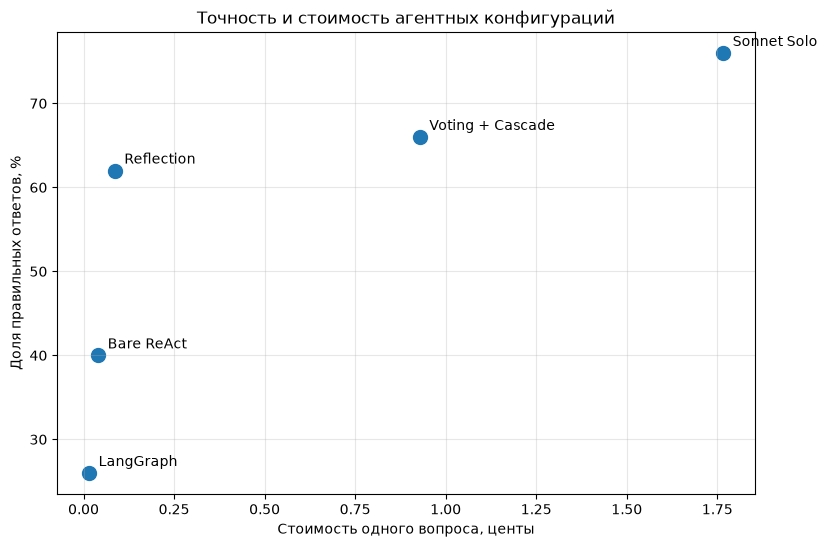

In [78]:
summary = pd.DataFrame([
    ["Bare ReAct", 40, 4.5, 2394, 0.0399, 0.0999],
    ["LangGraph", 26, 1.9, 853, 0.0147, 0.0567],
    ["Reflection", 62, 7.7, 5368, 0.0857, 0.1382],
    ["Voting + Cascade", 66, 14.02, 10174.9, 0.9280, 1.4060],
    ["Sonnet Solo", 76, 3.76, 4889.8, 1.7656, 2.3232]], columns=[ "Конфигурация", "Accuracy (%)", "Вызовов/вопрос", "Токенов/вопрос", "Центов/вопрос", "Центов/верный"])

display(summary)
Path("results").mkdir(exist_ok=True)
summary.to_csv("results/summary.csv", index=False)

plt.figure(figsize=(9, 6))
plt.scatter( summary["Центов/вопрос"], summary["Accuracy (%)"], s=100)

for _, row in summary.iterrows():
    plt.annotate( row["Конфигурация"], (row["Центов/вопрос"], row["Accuracy (%)"]), xytext=(7, 5), textcoords="offset points" )

plt.xlabel("Стоимость одного вопроса, центы")
plt.ylabel("Доля правильных ответов, %")
plt.title("Точность и стоимость агентных конфигураций")
plt.grid(alpha=0.3)
plt.savefig("results/accuracy_cost.png", dpi=150, bbox_inches="tight")
plt.show()

### Анализ Reflection: Fixed / Broken

повторный прогон LangGraph без критика (предыдущие результаты не были сохранены)

In [79]:
path = Path("results/langgraph_fixed_paired.csv")
rows = ( pd.read_csv(path).to_dict("records")  if path.exists() else [])
completed = {r["id"] for r in rows}

for i, task in enumerate(questions, 1):
    if task["id"] in completed:
        continue

    TAG["now"] = "langgraph_fixed_paired"

    try:
        answer = ask_langgraph(task["question"])
    except Exception as e:
        answer = f"ошибка: {type(e).__name__}"

    rows.append({ "id": task["id"], "answer": answer, "ok": is_correct(task, answer)})
    pd.DataFrame(rows).to_csv(path, index=False)
    print(f"{i}/50 | correct={rows[-1]['ok']}")


1/50 | correct=True
2/50 | correct=True
3/50 | correct=False
4/50 | correct=False
5/50 | correct=True
6/50 | correct=False
7/50 | correct=False
8/50 | correct=True
9/50 | correct=True
10/50 | correct=False
11/50 | correct=True
12/50 | correct=True
13/50 | correct=True
14/50 | correct=False
15/50 | correct=False
16/50 | correct=True
17/50 | correct=True
18/50 | correct=False
19/50 | correct=False
20/50 | correct=True
21/50 | correct=False
22/50 | correct=False
23/50 | correct=True
24/50 | correct=False
25/50 | correct=True
26/50 | correct=True
27/50 | correct=False
28/50 | correct=True
29/50 | correct=False
30/50 | correct=False
31/50 | correct=True
32/50 | correct=False
33/50 | correct=True
34/50 | correct=True
35/50 | correct=False
36/50 | correct=True
37/50 | correct=True
38/50 | correct=True
39/50 | correct=True
40/50 | correct=True
41/50 | correct=False
42/50 | correct=True
43/50 | correct=True
44/50 | correct=False
45/50 | correct=False
46/50 | correct=True
47/50 | correct=False
4

**считаем Fixed и Broken:**

In [80]:
baseline = pd.read_csv("results/langgraph_fixed_paired.csv")
reflection = pd.read_csv("results/langgraph_critic_v2.csv")

comparison = baseline.merge( reflection, on="id", suffixes=("_base", "_critic"))
valid = comparison[ ~comparison["answer_base"].astype(str).str.startswith("ошибка:")  & ~comparison["answer_critic"].astype(str).str.startswith("ошибка:")]
fixed = valid[ (~valid["ok_base"]) & valid["ok_critic"]]
broken = valid[valid["ok_base"] & (~valid["ok_critic"])]

print("Сопоставлено без технических ошибок:", len(valid))
print("Fixed:", len(fixed))
print("Broken:", len(broken))
print("Чистое улучшение:", len(fixed) - len(broken))
display(fixed[["id", "answer_base", "answer_critic"]])
display(broken[["id", "answer_base", "answer_critic"]])

Сопоставлено без технических ошибок: 50
Fixed: 2
Broken: 0
Чистое улучшение: 2


,id,answer_base,answer_critic
40,film-before-2024-06,The film that won Best Animated Feature at the...,The film that won Best Animated Feature at the...
43,film-before-2024-09,I don't know.,The Japanese film that won the 2022 Oscar for ...


,id,answer_base,answer_critic


### Ручная проверка ошибок

In [82]:
gold = pd.DataFrame(questions)[["id", "question", "answer"]]
gold = gold.rename(columns={"answer": "gold"})
pred = pd.read_csv("results/langgraph_critic_v2.csv")
pred = pred.rename(columns={"answer": "prediction"})
audit = gold.merge(pred, on="id")
audit = audit[~audit["ok"]].sample(  n=10,  random_state=42)

for _, row in audit.iterrows():
    print(f"\nID: {row['id']}")
    print("Вопрос:", row["question"])
    print("Эталон:", row["gold"])
    print("Ответ агента:", row["prediction"])
    print()


ID: music-2026-03
Вопрос: Which song won Song of the Year at the 2026 Grammy Awards?
Эталон: WILDFLOWER
Ответ агента: I don't know.


ID: film-2026-04
Вопрос: Which film won Best Animated Feature at the 2026 Oscars?
Эталон: KPop Demon Hunters
Ответ агента: I don't know.


ID: series-2026-04
Вопрос: Who received the 2026 Emmy for comedy-series directing for Widow's Bay?
Эталон: Hiro Murai
Ответ агента: I don't know.


ID: music-2026-04
Вопрос: Who won Best New Artist at the 2026 Grammy Awards?
Эталон: Olivia Dean
Ответ агента: I don't know.


ID: film-2026-09
Вопрос: Which film won the Golden Bear at the 2026 Berlin International Film Festival?
Эталон: Gelbe Briefe
Ответ агента: The film that won the Golden Bear at the 2026 Berlin International Film Festival is "Yellow Letters" by İlker Çatak.


ID: music-before-2024-10
Вопрос: Which Willie Nelson album won Best Country Album at the 2023 Grammys?
Эталон: A Beautiful Time
Ответ агента: I don't know.


ID: music-2026-07
Вопрос: Which alb

In [83]:
audit = audit.copy()
audit["manual_correct"] = ( audit["id"] == "film-2026-09")
audit["false_negative"] = ( ~audit["ok"] & audit["manual_correct"])
audit.to_csv( "results/manual_audit.csv", index=False)

print("Проверено:", len(audit))
print("Ложных ошибок метрики:", audit["false_negative"].sum())
print("Действительно неверных:", (~audit["manual_correct"]).sum())

Проверено: 10
Ложных ошибок метрики: 1
Действительно неверных: 9


### Ограничение количества вызовов модели

In [84]:
from langchain.agents.middleware import ModelCallLimitMiddleware

TAG["now"] = "model_call_limit"
before = len(CALLS)
capped = create_agent( lc_model(CHEAP_MODEL), tools=LC_TOOLS, system_prompt=SYSTEM_PROMPT,
    middleware=[ ModelCallLimitMiddleware(run_limit=2, exit_behavior="end")])

out = capped.invoke({  "messages": [{ "role": "user",
        "content": "Find who won Album of the Year and Song of the Year at the 2026 Grammys."}]})

print("Последнее сообщение:", str(out["messages"][-1].content)[:300])
print("Вызовов модели:", len(CALLS) - before)
print("Установленный лимит:", 2)

Последнее сообщение: Model call limits exceeded: run limit (2/2)
Вызовов модели: 2
Установленный лимит: 2


**Вывод:**  
При ограничении run_limit=2 агент выполнил ровно два вызова модели и завершил работу с сообщением о достижении лимита.  
Таким образом, ModelCallLimitMiddleware позволяет ограничивать количество запросов к LLM и контролировать расходы, даже если агент не успел решить задачу.